# Los predictores publicados en sus propias tablas de validación, reproducidos y puntuados con dos estadísticos

**Pregunta:** ¿Qué tan buenos son los predictores publicados en sus propias tablas de validación?

**Nivel 3: Estado del arte** · Requiere: 02-classical-prediction/01-the-classical-equation-on-one-blast, 02-classical-prediction/02-the-rock-factor · Tiempo de lectura: unos 30 minutos

## Objetivos

El estado del arte para este problema son dos artículos publicados que validan cada uno tres predictores en una tabla pequeña de validación e imprimen sus predicciones junto a las mediciones. Este notebook toma esas columnas impresas como referencia, las puntúa con el puntuador del motor, recalcula la regresión publicada desde sus propias ecuaciones y pone la columna clásica junto al predictor clásico del motor. La pregunta es qué tan buenos son realmente los predictores publicados en sus propias tablas, lo que también significa cuánto puede decir una tabla de 12 tiros.

Al terminar, usted habrá:

- puntuado las columnas impresas clásica, de regresión y de red en la tabla de 12 tiros con dos estadísticos con nombre, y visto que dan respuestas distintas a la misma columna;
- puesto un intervalo de 95 por ciento a cada puntaje, y visto cuán ancho es para 12 tiros;
- recalculado la regresión publicada desde sus ecuaciones en ambos conjuntos de validación y comparado con la columna que imprimieron los artículos;
- medido cuánto cambia el cuadro el único tiro que también es fila de entrenamiento.

## Preparación

Instale los paquetes con las versiones exactas de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

La celda de preparación siguiente importa los paquetes, imprime sus versiones instaladas para que la salida registre qué motor produjo cada número, fija el estilo de los gráficos y define `show_table`, un ayudante de cuatro líneas que dibuja filas como tabla Markdown porque el entorno de notebooks no tiene `pandas`.

In [1]:
# Importaciones, versiones fijadas, estilo de gráficos y un ayudante de tablas
from importlib.metadata import version

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def show_table(header, rows, left=1):
    # Dibujar las filas como tabla Markdown, las primeras `left` columnas a la izquierda y las demás a la derecha
    lines = ["| " + " | ".join(header) + " |", "|" + ":---|" * left + "---:|" * (len(header) - left)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    text = "\n".join(lines)
    display({"text/markdown": text, "text/plain": text}, raw=True)

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| El conjunto de validación de 13 tiros y las predicciones impresas del artículo de 2010 | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | `bf.load_holdout(protocol="2010")` dentro del paquete `blastfrag` |
| El conjunto de validación de 12 tiros y las predicciones impresas del artículo de 2012 (Kuz-Ram, regresión, red) | Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | `bf.load_holdout(protocol="2012")` y `protocol="union"` |
| Las ecuaciones de la regresión publicada, y el corpus de entrenamiento | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita | `bf.PublishedRegression` y `bf.load_training_corpus()` dentro del paquete |

Cada tiro de validación lleva, en sus metadatos, el valor que imprimió cada artículo para él, así que una columna impresa es un dato que el notebook puntúa como cualquier otra predicción. No se lee ningún archivo de `data/`.

## Método

Puntuar una columna de predicciones necesita dos estadísticos, porque esta literatura usa un mismo nombre para dos cantidades distintas.

- El **r2 de Pearson** es el cuadrado de la correlación entre los tamaños predichos y medidos, que cualquier recta de cualquier pendiente y desfase puede satisfacer.
- La **varianza explicada respecto de la línea de identidad** es `1 - SS_res / SS_tot`, con los residuos tomados contra `predicho = medido` y no contra una recta ajustada, así que penaliza el sesgo y una pendiente errónea.

`bf.score` del motor devuelve ambos con sus propios nombres (`pearson_r2`, `r2_identity`), y cada figura del producto dice cuál muestra. Un valor impreso pasa por exactamente el mismo puntuador que los predictores del propio motor una vez envuelto en una `Prediction`. Como la tabla tiene solo 12 tiros, cada puntaje recibe además un intervalo de 95 por ciento de `bf.bootstrap_interval`, que remuestrea los tiros con reposición 2000 veces y toma los percentiles 2,5 y 97,5 de los puntajes remuestreados. Tratar los 12 tiros como independientes es generoso, pues tres sitios aportan dos tiros cada uno, así que los intervalos son, si acaso, optimistas.

### Paso 1: las columnas impresas en la tabla de 12 tiros

La celda carga el conjunto de validación de 2012, envuelve cada columna impresa (Kuz-Ram, regresión, red) en objetos `Prediction`, y las puntúa con `bf.score`, que imprime ambos estadísticos. El modelo nulo, que predice la media de entrenamiento para cada tiro y no usa ninguna entrada, se puntúa sobre las mismas filas como la referencia que todo predictor debe superar.

In [2]:
# Puntuar cada columna impresa con el puntuador del motor, con la media de entrenamiento de referencia
train = bf.load_training_corpus()
holdout = bf.load_holdout(protocol="2012")
columns = {"Kuz-Ram (kuzram_2012)": "kuzram_2012", "regression (regression_2012)": "regression_2012",
           "network (nn_mean_2012)": "nn_mean_2012"}
printed = {}
for column in columns.values():
    values = [b.meta["published"][column] for b in holdout]
    printed[column] = [bf.Prediction(method=column, blast_id=b.blast_id, x50_m=v) for b, v in zip(holdout, values)]
null = bf.null_model_score(holdout, training_mean_m=bf.training_mean(train))
rows = []
for label, column in columns.items():
    s = bf.score(holdout, printed[column], method=column)
    rows.append((label, f"{s.pearson_r2:.4f}", f"{s.r2_identity:.4f}", f"{s.rmse_m:.4f}", f"{s.bias_m:+.4f}"))
rows.append(("nulo (media de entrenamiento)", "-", f"{null.r2_identity:.4f}", f"{null.rmse_m:.4f}",
             f"{null.bias_m:+.4f}"))
header = ["columna impresa", "r2 de Pearson", "r2 respecto de la identidad",
          "RMSE (m)", "sesgo (m)"]
show_table(header, rows)

| columna impresa | r2 de Pearson | r2 respecto de la identidad | RMSE (m) | sesgo (m) |
|:---|---:|---:|---:|---:|
| Kuz-Ram (kuzram_2012) | 0.5698 | 0.2318 | 0.1279 | +0.0033 |
| regression (regression_2012) | 0.8197 | 0.7082 | 0.0788 | -0.0483 |
| network (nn_mean_2012) | 0.9372 | 0.9096 | 0.0439 | -0.0242 |
| nulo (media de entrenamiento) | - | -0.0093 | 0.1466 | -0.0141 |

Una misma columna tiene dos puntajes. La columna Kuz-Ram impresa tiene un r2 de Pearson de 0,5698 pero una varianza explicada respecto de la identidad de solo 0,2318: sus tamaños están correlacionados con las mediciones sin estar cerca de ellas. La regresión alcanza 0,7082 en el estadístico de identidad (0,8197 como correlación) y la red 0,9096 (0,9372). El modelo nulo puntúa -0,0093, así que los tres predictores superan a una constante, el clásico por poco: su RMSE es 0,1279 m contra 0,1466 m. Una tabla que informara solo la correlación ubicaría a la columna clásica más alto de lo que merece.

Un puntaje sobre 12 tiros es una estimación puntual con una sombra ancha. La celda remuestrea los 12 tiros con reposición 2000 veces para cada columna, recalcula la varianza explicada respecto de la identidad en cada remuestreo, e informa los percentiles 2,5 y 97,5. El ancho del intervalo es el tamaño honesto de lo que la tabla puede afirmar.

In [3]:
# Un intervalo de 95 por ciento para cada varianza explicada, remuestreando los 12 tiros 2000 veces
rows = []
for label, column in columns.items():
    point, low, high = bf.bootstrap_interval(holdout, printed[column], "r2_identity", n_boot=2000, unit="blast", seed=0)
    rows.append((label, f"{point:.3f}", f"{low:.3f} a {high:.3f}", f"{high - low:.2f}"))
header = ["columna impresa", "r2 respecto de la identidad", "intervalo 95 %",
          "ancho del intervalo"]
show_table(header, rows)

| columna impresa | r2 respecto de la identidad | intervalo 95 % | ancho del intervalo |
|:---|---:|---:|---:|
| Kuz-Ram (kuzram_2012) | 0.232 | -1.811 a 0.857 | 2.67 |
| regression (regression_2012) | 0.708 | -0.022 a 0.874 | 0.90 |
| network (nn_mean_2012) | 0.910 | 0.648 a 0.974 | 0.33 |

Los intervalos son anchos. La columna Kuz-Ram, 0,232, abarca de -1,811 a 0,857, un ancho de 2,67; la regresión, 0,708, abarca de -0,022 a 0,874; la red, 0,910, abarca de 0,648 a 0,974. Solo el intervalo de la red queda lejos de cero. Así que el orden de las tres columnas se ve en los puntajes puntuales, pero el intervalo de la regresión queda casi por completo dentro del de la columna clásica: con 12 tiros la tabla no puede separarlas. La celda siguiente muestra las tres columnas contra las mediciones.

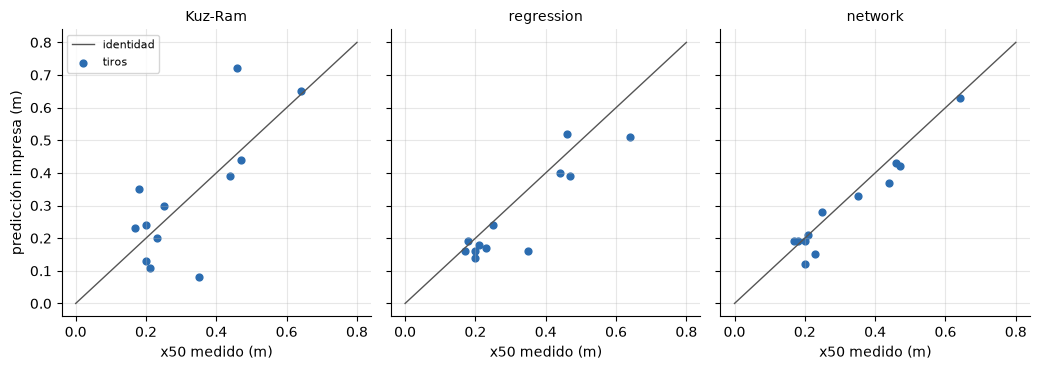

In [4]:
# Predicciones impresas contra las mediciones de los tres predictores publicados, con la línea de identidad
measured = np.array([b.x50_m for b in holdout])
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.8), sharex=True, sharey=True)
for ax, (label, column) in zip(axes, columns.items()):
    values = np.array([p.x50_m for p in printed[column]])
    ax.plot([0, 0.8], [0, 0.8], color="#555", lw=1, label="identidad")
    ax.scatter(measured, values, s=24, color="#2b6cb0", label="tiros")
    ax.set_title(label.split(" (")[0], fontsize=10)
    ax.set_xlabel("x50 medido (m)")
axes[0].set_ylabel("predicción impresa (m)")
axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

Cada panel grafica una columna impresa contra el tamaño medido, con la línea de identidad. Los puntos de la red se pegan a la línea; los de la regresión la siguen con un sesgo bajo y dos errores grandes; los puntos Kuz-Ram se dispersan ampliamente a su alrededor, con un tiro predicho en cerca de 0,72 m que midió 0,46 m y otro predicho en cerca de 0,08 m que midió 0,35 m. Los paneles muestran de dónde salen los puntajes de la tabla, tiro a tiro. No muestran cómo se comportan los predictores en una mina que no han visto: los 12 tiros vienen de sitios que también están en la tabla de entrenamiento.

## Estado del arte

Tres artículos definen lo que ya se sabe, y cada uno valida en una tabla fija pequeña.

- **Hudaverdi, Kulatilake y Kuzu 2010** (https://doi.org/10.1002/nag.957) ajustan una regresión a los 97 tiros, derivan cada tiro a uno de dos grupos de rigidez de la roca con un discriminante, y validan en un hold-out de 13 tiros contra una columna Kuz-Ram.
- **Kulatilake, Hudaverdi y Wu 2012** (https://doi.org/10.1007/s10706-012-9496-3) agregan una red de retropropagación (siete entradas, una capa oculta, Levenberg-Marquardt, una red por grupo) y validan los tres predictores en un hold-out de 12 tiros. El SDD registra que el ajuste de paridad publicado de la columna Kuz-Ram en ese hold-out es 0,5697, que es el r2 de Pearson que el Paso 1 reproduce como 0,5698.
- **Amoako, Jha y Zhong 2022** (https://doi.org/10.3390/mining2020013) reimprimen la ecuación clásica y sus correcciones, que sigue el predictor clásico del motor.

Ambas validaciones informan una tabla de predicciones en un hold-out fijo pequeño, con la correlación como estadístico principal. Las celdas siguientes ejecutan la regresión publicada y el predictor clásico del motor sobre esos mismos tiros y los comparan con las columnas impresas.

### Paso 2: la regresión publicada, recalculada

La regresión del artículo de 2010 son dos leyes de potencia, una por grupo de rigidez de la roca, con un discriminante que deriva cada tiro. `PublishedRegression` del motor aplica las ecuaciones tal como se imprimen. La celda la aplica a los tiros de cada conjunto de validación y puntúa el resultado contra la columna que imprimieron los artículos para los mismos tiros, con el intervalo de remuestreo de cada una. Si la tabla impresa y las ecuaciones impresas concuerdan, las dos columnas deberían coincidir.

In [5]:
# La regresión publicada recalculada desde sus ecuaciones frente a la columna impresa, en ambos conjuntos de validación
union = bf.load_holdout(protocol="union")
regression = bf.PublishedRegression()
comparison = {}
for year in ("2010", "2012"):
    column = f"regression_{year}"
    rows_year = [b for b in union if b.meta["published"][column] is not None]
    values = [b.meta["published"][column] for b in rows_year]
    as_printed = [bf.Prediction(method=column, blast_id=b.blast_id, x50_m=v) for b, v in zip(rows_year, values)]
    comparison[year] = (rows_year, as_printed, regression.predict(rows_year))
rows = []
for year, (rows_year, as_printed, recomputed) in comparison.items():
    first = bf.bootstrap_interval(rows_year, as_printed, "r2_identity", n_boot=2000, unit="blast", seed=0)
    second = bf.bootstrap_interval(rows_year, recomputed, "r2_identity", n_boot=2000, unit="blast", seed=0)
    rows.append((year, len(rows_year), f"{first[0]:.4f}", f"{second[0]:.4f}", f"{second[0] - first[0]:+.4f}",
                 f"{first[1]:.2f} a {first[2]:.2f}", f"{second[1]:.2f} a {second[2]:.2f}"))
header = ["conjunto", "n", "impreso", "recalculado", "ganancia",
          "intervalo, impreso", "intervalo, recalculado"]
show_table(header, rows)

| conjunto | n | impreso | recalculado | ganancia | intervalo, impreso | intervalo, recalculado |
|:---|---:|---:|---:|---:|---:|---:|
| 2010 | 13 | 0.7467 | 0.8537 | +0.1070 | -0.18 a 0.89 | 0.61 a 0.91 |
| 2012 | 12 | 0.7082 | 0.8272 | +0.1190 | -0.02 a 0.87 | 0.65 a 0.88 |

No coinciden. En el conjunto de 2010 de 13 tiros, la regresión recalculada explica 0,8537 de la varianza contra 0,7467 de la columna impresa, una ganancia de 0,1070; en el conjunto de 2012 de 12 tiros, 0,8272 contra 0,7082, una ganancia de 0,1190. La tabla que imprimieron los artículos no es entonces lo que producen sus propias ecuaciones, y las ecuaciones lo hacen mejor. Los intervalos, sin embargo, se traslapan: de -0,18 a 0,89 contra 0,61 a 0,91 en 2010, y de -0,02 a 0,87 contra 0,65 a 0,88 en 2012, así que con tantos tiros la ganancia es menor que la incertidumbre de cualquiera de los dos puntajes.

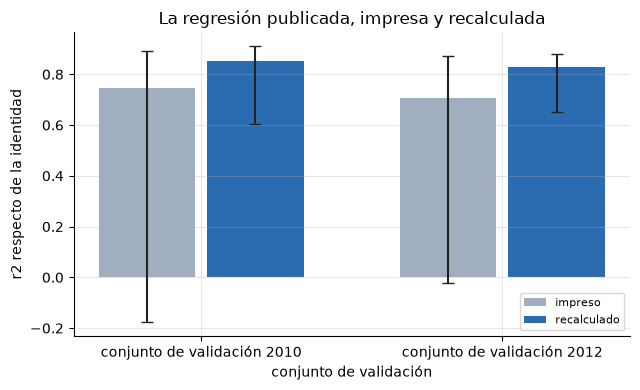

In [6]:
# Varianza explicada respecto de la identidad, impreso contra recalculado, con los intervalos de 95 por ciento
fig, ax = plt.subplots(figsize=(6.5, 4))
for offset, (kind, color) in zip((-0.18, 0.18), (("impreso", "#a0aec0"), ("recalculado", "#2b6cb0"))):
    for position, (year, (rows_year, as_printed, recomputed)) in enumerate(comparison.items()):
        predictions = as_printed if offset < 0 else recomputed
        interval = bf.bootstrap_interval(rows_year, predictions, "r2_identity", n_boot=2000, unit="blast", seed=0)
        point, low, high = interval
        ax.bar(position + offset, point, width=0.32, color=color, label=kind if position == 0 else None)
        ax.errorbar(position + offset, point, yerr=[[point - low], [high - point]], color="#222", capsize=4)
ax.set_xticks(range(len(comparison)), [f"conjunto de validación {year}" for year in comparison])
ax.set_xlabel("conjunto de validación")
ax.set_ylabel("r2 respecto de la identidad")
ax.set_title("La regresión publicada, impresa y recalculada")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

Cada par de barras es un conjunto de validación: gris para la columna tal como se imprimió, azul para la regresión recalculada desde las ecuaciones, con un bigote negro para el intervalo de 95 por ciento. Las barras azules son más altas en ambos conjuntos y sus bigotes son mucho más cortos, lo que dice que las predicciones recalculadas son más consistentes entre remuestreos; los bigotes grises llegan bajo cero. La figura muestra una diferencia entre una tabla impresa y unas ecuaciones impresas. No muestra cuál de las dos lleva un descuido: eso necesitaría el trabajo propio de los artículos, que el corpus no tiene.

### Paso 3: la columna clásica y el predictor clásico del motor

La columna Kuz-Ram impresa y el predictor `Kuznetsov` del motor, que usa el factor de roca por sitio recuperado de esa misma columna (notebook anterior), deberían coincidir casi del todo; la diferencia es el redondeo de los valores impresos a dos decimales. La celda lista ambos lado a lado para los 12 tiros con el tamaño medido y la brecha.

In [7]:
# La columna Kuz-Ram impresa junto al predictor clásico del motor, tiro a tiro
classical = bf.Kuznetsov().predict(holdout)
rows = []
for blast, prediction in zip(holdout, classical):
    shown = blast.meta["published"]["kuzram_2012"]
    gap = abs(prediction.x50_m - shown)
    sizes = (f"{blast.x50_m:.2f}", f"{shown:.2f}", f"{prediction.x50_m:.3f}", f"{gap:.3f}")
    rows.append((blast.blast_id, blast.site, *sizes))
header = ["tiro", "sitio", "medido (m)", "impreso (m)", "motor (m)",
          "brecha (m)"]
show_table(header, rows, left=2)
print("mayor brecha, columna impresa contra motor (m):", max(float(r[5]) for r in rows))

| tiro | sitio | medido (m) | impreso (m) | motor (m) | brecha (m) |
|:---|:---|---:|---:|---:|---:|
| En13 | Enusa | 0.47 | 0.44 | 0.440 | 0.000 |
| Ru7 | Reocin-UG | 0.64 | 0.65 | 0.650 | 0.000 |
| Mg8 | Murgul | 0.44 | 0.39 | 0.387 | 0.003 |
| Mg9 | Murgul | 0.25 | 0.30 | 0.302 | 0.002 |
| Rc1 | Reocin | 0.46 | 0.72 | 0.720 | 0.000 |
| Mr12 | Mrica | 0.20 | 0.24 | 0.240 | 0.000 |
| Db10 | Dongri-Buzurg | 0.35 | 0.08 | 0.080 | 0.000 |
| Sm8 | Soma | 0.18 | 0.35 | 0.350 | 0.000 |
| Oz8 | Ozmert | 0.23 | 0.20 | 0.198 | 0.002 |
| Oz9 | Ozmert | 0.17 | 0.23 | 0.232 | 0.002 |
| Ad23 | Akdaglar | 0.21 | 0.11 | 0.108 | 0.002 |
| Ad24 | Akdaglar | 0.20 | 0.13 | 0.132 | 0.002 |

mayor brecha, columna impresa contra motor (m): 0.003


La mayor brecha entre la columna impresa y el motor es 0,003 m, bajo el redondeo de los valores impresos, así que el motor reproduce la columna clásica publicada desde la ecuación publicada y los factores recuperados. Ese acuerdo es una verificación de consistencia de la reconstrucción de la geometría y de los factores, no evidencia independiente de habilidad: los factores se recuperaron de esta misma columna. Las dos columnas comparten además sus errores, por ejemplo Rc1, impreso 0,72 m contra 0,46 m medido, y Db10, impreso 0,08 m contra 0,35 m. La tabla dice que el predictor clásico del motor es el publicado; no dice que sea exacto.

### Paso 4: el tiro que también es fila de entrenamiento

Uno de los 12 tiros de validación es también una fila de la tabla de entrenamiento, que un hold-out debe mantener aparte; el motor lo marca en los metadatos del tiro. La celda puntúa las tres columnas impresas sobre los 12 tiros y sobre los 11 que quedan sin él, e imprime el cambio en la varianza explicada respecto de la identidad.

In [8]:
# Puntuar las tres columnas impresas con y sin el tiro que también es fila de entrenamiento
leaked = [b.blast_id for b in holdout if b.meta["in_training_table"]]
keep = [i for i, b in enumerate(holdout) if not b.meta["in_training_table"]]
clean = [holdout[i] for i in keep]
effect = {}
for label, column in columns.items():
    full = bf.score(holdout, printed[column]).r2_identity
    without = bf.score(clean, [printed[column][i] for i in keep]).r2_identity
    effect[label] = (full, without)
rows = [(label, f"{full:.4f}", f"{without:.4f}", f"{without - full:+.4f}") for label, (full, without) in effect.items()]
show_table(["columna impresa", "n = 12", "n = 11", "cambio"], rows)
print("tiro en el conjunto de validación y en la tabla de entrenamiento:", leaked)

| columna impresa | n = 12 | n = 11 | cambio |
|:---|---:|---:|---:|
| Kuz-Ram (kuzram_2012) | 0.2318 | 0.4478 | +0.2160 |
| regression (regression_2012) | 0.7082 | 0.6956 | -0.0126 |
| network (nn_mean_2012) | 0.9096 | 0.9048 | -0.0048 |

tiro en el conjunto de validación y en la tabla de entrenamiento: ['Rc1']


El tiro compartido es Rc1, y quitarlo mueve la columna Kuz-Ram de 0,2318 a 0,4478, un aumento de 0,2160, mientras la regresión y la red se mueven solo -0,0126 y -0,0048. Rc1 es el tiro que la columna clásica predijo en 0,72 m contra 0,46 m medidos, así que una fila de 12 explica 0,2160 del puntaje clásico. Una tabla fija de 12 tiros es sensible a una sola fila, y la columna clásica es la más sensible. La tabla no dice que el tiro compartido filtró información a las predicciones impresas; dice solo cuánto depende de él el puntaje.

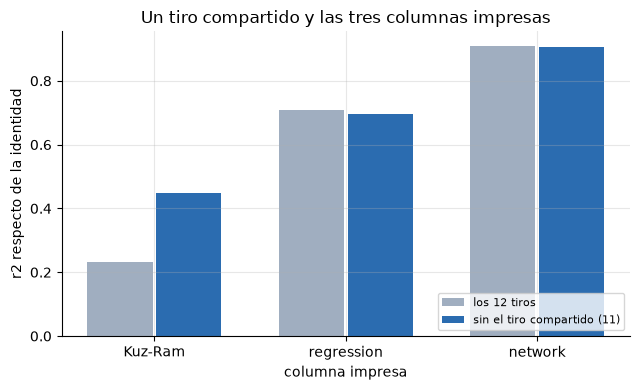

In [9]:
# Varianza explicada con los 12 tiros y con los 11 que no son filas de entrenamiento, para cada columna impresa
labels = [label.split(" (")[0] for label in effect]
positions = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(positions - 0.18, [v[0] for v in effect.values()], width=0.34, color="#a0aec0", label="los 12 tiros")
ax.bar(positions + 0.18, [v[1] for v in effect.values()], width=0.34, color="#2b6cb0",
       label="sin el tiro compartido (11)")
ax.set_xticks(positions, labels)
ax.set_ylabel("r2 respecto de la identidad")
ax.set_xlabel("columna impresa")
ax.set_title("Un tiro compartido y las tres columnas impresas")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

Las barras grises son la varianza explicada con los 12 tiros y las azules con los 11 que no son filas de entrenamiento, para cada columna impresa. El par clásico es el único que cambia visiblemente, con la barra azul muy por encima de la gris, mientras que los pares de regresión y de red son casi idénticos. La imagen muestra que el efecto de una fila depende del predictor: una columna que falla mucho en esa fila gana bastante cuando la fila sale, y una que ya la predice bien casi no se mueve. No da un puntaje correcto para la columna clásica, solo un segundo puntaje que depende de una elección.

## Resultados

**Respuesta:** En su propia tabla de 12 tiros los predictores publicados puntúan, en la varianza explicada respecto de la identidad, 0,2318 la columna Kuz-Ram, 0,7082 la regresión y 0,9096 la red, contra -0,0093 de una constante, y la misma columna Kuz-Ram tiene un r2 de Pearson de 0,5698: una tabla que informara solo la correlación ubicaría a la columna clásica más alto de lo que merece. Los intervalos son anchos (-1,811 a 0,857, -0,022 a 0,874 y 0,648 a 0,974), así que solo la red es claramente mejor que una constante. Recalculada desde sus ecuaciones, la regresión publicada explica 0,8537 y 0,8272 de la varianza en los dos conjuntos, 0,1070 y 0,1190 más que las tablas impresas; el predictor clásico del motor reproduce la columna Kuz-Ram impresa a 0,003 m; y quitar el único tiro que también es fila de entrenamiento sube el puntaje clásico de 0,2318 a 0,4478.

**Qué se sigue.** Un puntaje publicado sobre 12 tiros es una base débil para ordenar predictores, y el orden puede cambiar con una fila. La tabla impresa y las ecuaciones impresas del mismo artículo discrepan, así que quien reproduzca la regresión debe aplicar las ecuaciones y no copiar la tabla.

**Lo que este notebook no muestra.** Todo esto es sobre 12 o 13 tiros de sitios que también están en la tabla de entrenamiento, así que nada de ello dice cómo se comporta un predictor en una mina que no ha visto. El acuerdo de la columna clásica con el motor es en parte circular, porque los factores se recuperaron de esa columna. Y el notebook no puede decir cuál de la tabla impresa y las ecuaciones impresas es la errónea. Cómo les va a los predictores cuando se dejan fuera campañas completas es la pregunta del tema 04.

## Resumen

- Una columna de predicciones impresa se puede puntuar como cualquier otra predicción, y dos estadísticos que comparten nombre dan respuestas distintas sobre la misma columna (0,5698 contra 0,2318 en Kuz-Ram).
- Con 12 tiros cada puntaje tiene un intervalo ancho, y solo la red es claramente mejor que una constante.
- La regresión publicada, aplicada desde sus ecuaciones, explica 0,1070 y 0,1190 más varianza que las tablas impresas para ella, aunque los intervalos se traslapan.
- El predictor clásico del motor coincide con la columna Kuz-Ram impresa a 0,003 m porque sus factores de roca se recuperaron de esa columna.
- Un tiro que también es fila de entrenamiento mueve el puntaje clásico de 0,2318 a 0,4478.
- Siguiente: el notebook 04 pregunta cuánto del puntaje clásico sobrevive cuando el sitio no se conoce de antemano (nivel 4).

## Referencias

- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (la regresión, el discriminante, el conjunto de validación de 13 tiros)
- Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (la red y el conjunto de validación de 12 tiros)
- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (la ecuación clásica tal como se reimprime)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/